Environment Setup & Data Loading
Import required libraries for exploration and load the raw dataset.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../data/Reviews.csv")

# Quick inspection
df.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


Initial Data Inspection
Check dataset shape, column types, and missing values.

In [3]:
print("Dataset Shape:", df.shape)
print("\nData Info:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (568454, 10)

Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   Id                      568454 non-null  int64 
 1   ProductId               568454 non-null  object
 2   UserId                  568454 non-null  object
 3   ProfileName             568428 non-null  object
 4   HelpfulnessNumerator    568454 non-null  int64 
 5   HelpfulnessDenominator  568454 non-null  int64 
 6   Score                   568454 non-null  int64 
 7   Time                    568454 non-null  int64 
 8   Summary                 568427 non-null  object
 9   Text                    568454 non-null  object
dtypes: int64(5), object(5)
memory usage: 43.4+ MB

Missing Values:
Id                         0
ProductId                  0
UserId                     0
ProfileName               26
HelpfulnessNumerator       0


Target Distribution (Score Analysis)
Analyze the distribution of rating scores (1 to 5 stars) to identify class imbalance.

Score Counts:
 Score
1     52268
2     29769
3     42640
4     80655
5    363122
Name: count, dtype: int64


/tmp/ipykernel_16404/2432164051.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Score', palette='viridis')


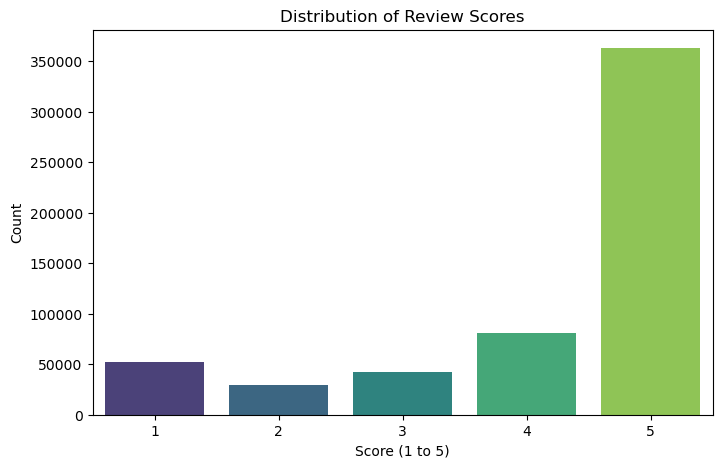

In [4]:
# Score distribution
score_counts = df['Score'].value_counts().sort_index()
print("Score Counts:\n", score_counts)

# Plot ratings distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Score', palette='viridis')
plt.title('Distribution of Review Scores')
plt.xlabel('Score (1 to 5)')
plt.ylabel('Count')
plt.show()

Cleaning & Filtering Experiments
Drop non-informative metadata, remove null values, and exclude neutral reviews (Score = 3).

In [5]:
# Drop metadata columns
df_clean = df.drop(columns=['Id', 'UserId', 'ProfileName'])

# Drop missing summaries
df_clean = df_clean.dropna(subset=['Summary']).copy()

# Remove neutral scores
df_clean = df_clean[df_clean['Score'] != 3].copy()

# Map binary sentiment (1: Positive > 3, 0: Negative < 3)
df_clean['Sentiment'] = df_clean['Score'].apply(lambda x: 1 if x > 3 else 0)

# Check class balance
print("Sentiment Ratio:")
print(df_clean['Sentiment'].value_counts(normalize=True))

Sentiment Ratio:
Sentiment
1    0.844021
0    0.155979
Name: proportion, dtype: float64


Text Feature Exploration
Combine Summary and Text fields, then inspect character and word counts.

In [6]:
# Combine text fields
df_clean['combined_text'] = df_clean['Summary'] + " " + df_clean['Text']

# Calculate review length (word count)
df_clean['word_count'] = df_clean['combined_text'].apply(lambda x: len(str(x).split()))

# Summary statistics of word counts by sentiment
df_clean.groupby('Sentiment')['word_count'].describe()

,count,mean,std,min,25%,50%,75%,max
Sentiment,,,,,,,,
0,82012.0,92.685131,89.851918,6.0,42.0,68.0,112.0,2157.0
1,443777.0,81.305122,76.985258,4.0,36.0,58.0,98.0,2526.0


Review Length Visualizations
Compare the review length distribution between positive and negative sentiments.

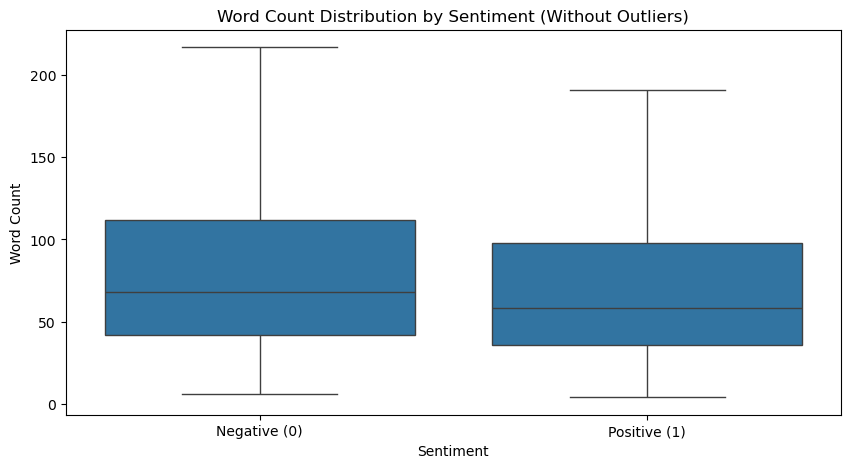

In [7]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_clean, x='Sentiment', y='word_count', showfliers=False)
plt.title('Word Count Distribution by Sentiment (Without Outliers)')
plt.xticks([0, 1], ['Negative (0)', 'Positive (1)'])
plt.ylabel('Word Count')
plt.show()